# Guía de Laboratorio GL09: Regresión lineal en dos caminos
**Materia:** Machine Learning (INF672)  
**Estudiante:** Juan David Canaza Zenteno  
**Institución:** Universidad Autónoma "Tomás Frías" (UATF) — Carrera de Ingeniería Informática  
**Fecha:** 30 de Septiembre 2026  

---
## 1. Configuración inicial y generación de datos simulados
Se inicializan las librerías necesarias (`numpy`, `matplotlib`, `scikit-learn`) y la paleta de colores requerida.

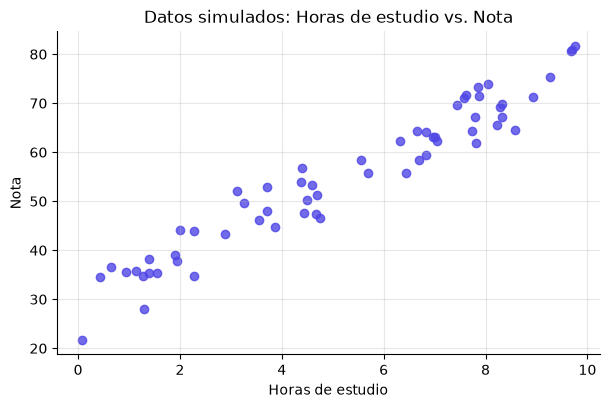

In [8]:
import numpy as np
import matplotlib.pyplot as plt

INDIGO, PURPURA, CORAL, TINTA = '#4F46E5', '#7E22CE', '#F43F5E', '#111827'
plt.rcParams.update({
    'figure.figsize': (7, 4.2),
    'axes.grid': True, 
    'grid.alpha': 0.3,
    'axes.spines.top': False,
    'axes.spines.right': False
})

rng = np.random.default_rng(42)
m = 60
horas = rng.uniform(0, 10, m)
nota = 30 + 5 * horas + rng.normal(0, 5, m)

plt.scatter(horas, nota, color=INDIGO, alpha=0.8)
plt.xlabel('Horas de estudio')
plt.ylabel('Nota')
plt.title('Datos simulados: Horas de estudio vs. Nota')
plt.show()

## 2. Parte A: Regresión lineal con `scikit-learn`
En esta sección dividimos el dataset en conjuntos de entrenamiento (80%) y prueba (20%), entrenamos un modelo de `LinearRegression` de la librería `scikit-learn` y evaluamos métricas clave de desempeño ($MAE$, $MSE$, $RMSE$, $R^2$).

Pendiente w_sk = 5.0675 (valor teórico real: 5)
Intercepto b_sk = 28.5394 (valor teórico real: 30)

Métricas de evaluación (scikit-learn):
 - MAE:  2.781 puntos
 - MSE:  12.188
 - RMSE: 3.491 puntos
 - R²:   0.946


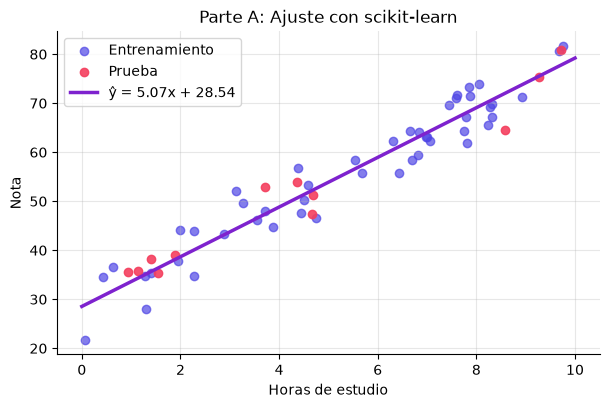

In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

X = horas.reshape(-1, 1)
y = nota

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0
)

modelo = LinearRegression()
modelo.fit(X_train, y_train)

w_sk = modelo.coef_[0]
b_sk = modelo.intercept_

print(f'Pendiente w_sk = {w_sk:.4f} (valor teórico real: 5)')
print(f'Intercepto b_sk = {b_sk:.4f} (valor teórico real: 30)')

y_pred = modelo.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f'\nMétricas de evaluación (scikit-learn):')
print(f' - MAE:  {mae:.3f} puntos')
print(f' - MSE:  {mse:.3f}')
print(f' - RMSE: {rmse:.3f} puntos')
print(f' - R²:   {r2:.3f}')

xs = np.linspace(0, 10, 100).reshape(-1, 1)
plt.scatter(X_train, y_train, color=INDIGO, alpha=0.7, label='Entrenamiento')
plt.scatter(X_test, y_test, color=CORAL, alpha=0.9, label='Prueba')
plt.plot(xs, modelo.predict(xs), color=PURPURA, lw=2.5, label=f'ŷ = {w_sk:.2f}x + {b_sk:.2f}')
plt.xlabel('Horas de estudio')
plt.ylabel('Nota')
plt.title('Parte A: Ajuste con scikit-learn')
plt.legend()
plt.show()

## 3. Parte B: Descenso de gradiente desde cero (Procesamiento vectorizado)
Implementamos la función de costo del Error Cuadrático Medio ($J(w, b)$) y sus gradientes de forma manual con `numpy`.
- $J(w, b) = \frac{1}{2m} \sum_{i=1}^m (\hat{y}^{(i)} - y^{(i)})^2$
- $\frac{\partial J}{\partial w} = \frac{1}{m} \sum_{i=1}^m (\hat{y}^{(i)} - y^{(i)}) \cdot x^{(i)}$
- $\frac{\partial J}{\partial b} = \frac{1}{m} \sum_{i=1}^m (\hat{y}^{(i)} - y^{(i)})$

Proceso de convergencia (Descenso de Gradiente):
 Iteración     0: w =  3.3986, b =   0.5598, J =  702.4903
 Iteración    10: w =  8.9765, b =   1.9226, J =   77.3678
 Iteración   100: w =  8.3954, b =   6.1889, J =   56.6861
 Iteración  1000: w =  5.6493, b =  24.6320, J =    8.7716
 Iteración  9999: w =  5.0675, b =  28.5394, J =    7.2610


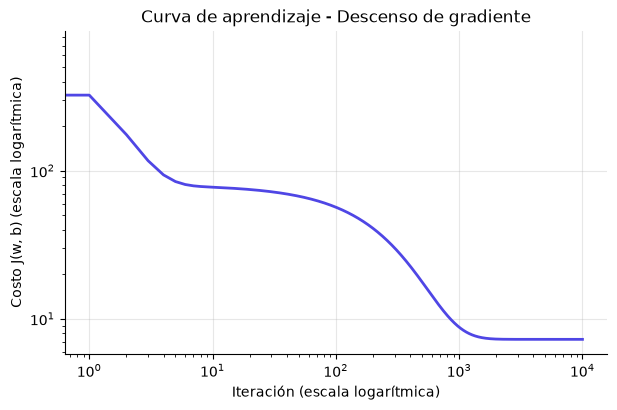

In [10]:
x_tr, x_te = X_train.ravel(), X_test.ravel()

def costo(w, b, x, y):
    """Calcula el costo del error cuadrático medio (MSE / 2)"""
    y_pred = w * x + b
    return np.mean((y_pred - y) ** 2) / 2

def gradientes(w, b, x, y):
    """Calcula las derivadas parciales dJ/dw y dJ/db"""
    error = (w * x + b) - y
    dw = np.mean(error * x)
    db = np.mean(error)
    return dw, db

def descenso_gradiente(x, y, alpha=0.01, iteraciones=10_000):
    """Ejecuta el bucle del descenso de gradiente acumulando el historial de costo"""
    w, b = 0.0, 0.0
    historial_costo = []
    
    print('Proceso de convergencia (Descenso de Gradiente):')
    for i in range(iteraciones):
        dw, db = gradientes(w, b, x, y)
        w = w - alpha * dw
        b = b - alpha * db
        costo_actual = costo(w, b, x, y)
        historial_costo.append(costo_actual)
        
        if i in (0, 10, 100, 1000, iteraciones - 1):
            print(f' Iteración {i:>5}: w = {w:7.4f}, b = {b:8.4f}, J = {costo_actual:9.4f}')
            
    return w, b, historial_costo

w_gd, b_gd, historial = descenso_gradiente(x_tr, y_train, alpha=0.01, iteraciones=10_000)

plt.plot(historial, color=INDIGO, lw=2)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Iteración (escala logarítmica)')
plt.ylabel('Costo J(w, b) (escala logarítmica)')
plt.title('Curva de aprendizaje - Descenso de gradiente')
plt.show()

## 4. Comparación final entre ambos métodos
Comparamos cuantitativamente los parámetros $w$ y $b$ obtenidos por el enfoque numérico (`scikit-learn`) y la solución iterativa manual (`Descenso de gradiente`).

Método                   |  Pendiente (w) | Intercepto (b)
----------------------------------------------------------
Valor real de la función |         5.0000 |        30.0000
scikit-learn             |         5.0675 |        28.5394
Descenso de gradiente    |         5.0675 |        28.5394
----------------------------------------------------------
Diferencia absoluta |w_sk - w_gd|: 1.55e-08
Diferencia absoluta |b_sk - b_gd|: 1.04e-07


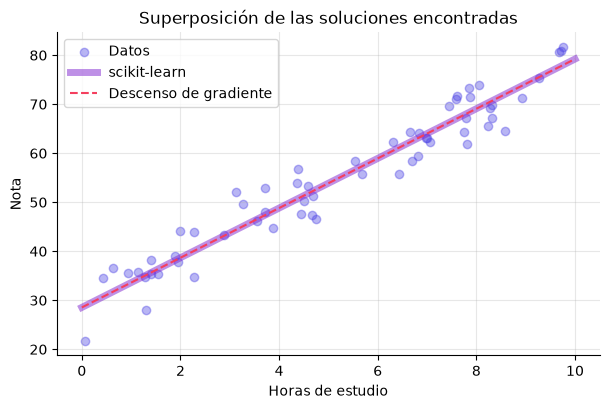

In [11]:
print(f'{"Método":24} | {"Pendiente (w)":>14} | {"Intercepto (b)":>14}')
print('-' * 58)
print(f'{"Valor real de la función":24} | {5.0:>14.4f} | {30.0:>14.4f}')
print(f'{"scikit-learn":24} | {w_sk:>14.4f} | {b_sk:>14.4f}')
print(f'{"Descenso de gradiente":24} | {w_gd:>14.4f} | {b_gd:>14.4f}')
print('-' * 58)
print(f'Diferencia absoluta |w_sk - w_gd|: {abs(w_sk - w_gd):.2e}')
print(f'Diferencia absoluta |b_sk - b_gd|: {abs(b_sk - b_gd):.2e}')

xs_flat = xs.ravel()
plt.scatter(horas, nota, color=INDIGO, alpha=0.4, label='Datos')
plt.plot(xs_flat, modelo.predict(xs), color=PURPURA, lw=5, alpha=0.5, label='scikit-learn')
plt.plot(xs_flat, w_gd * xs_flat + b_gd, color=CORAL, lw=1.5, ls='--', label='Descenso de gradiente')
plt.xlabel('Horas de estudio')
plt.ylabel('Nota')
plt.title('Superposición de las soluciones encontradas')
plt.legend()
plt.show()